# 02 Explore labels and years

Explores the resistance labels and collection years, and uses them to choose the main antibiotics and the time split.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import sys

src_dir = Path("../src").resolve()
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

import data
ANTIBIOTICS = data.ANTIBIOTICS
X, labels, year, clusters = data.load_data()

## Labels

In [4]:
X.shape

(1936, 16933)

In [5]:
pd.unique(labels.to_numpy().ravel())

array(['S', 'R', nan], dtype=object)

In [6]:
rows = []
for antibiotic in ANTIBIOTICS:
    count = labels[antibiotic].value_counts(dropna=False)
    rows.append(count)
    
summary = pd.DataFrame(rows, index=ANTIBIOTICS).fillna(0).astype(int)
summary = summary.rename(columns={np.nan: "Missing"})
summary['pct_R'] = round(summary['R'] / (summary['R'] + summary['S']) * 100, 2)
summary = summary.sort_values(by='pct_R', ascending=False)

summary

,S,R,Missing,pct_R
AMP,212,629,1095,74.79
AMX,432,662,842,60.51
TMP,485,356,1095,42.33
CET,497,344,1095,40.90
AMC,1168,512,256,30.48
TBM,596,245,1095,29.13
CXM,1415,520,1,26.87
CIP,1506,429,1,22.17
CTX,1476,383,77,20.60
GEN,1651,284,1,14.68


In [7]:
main_antibiotics = ["CIP", "GEN", "CXM"]

### Interpretation

AMP, TMP, CET and TBM were tested on about 841 strains, over 800 missing. All 12 antibiotics have at least 100 resistant strains, so all are included in the supplementary table.

The main antibiotics are chosen by where resistance comes from:
- **CIP** (ciprofloxacin): resistance mainly from mutations, which the gene table cannot see.
- **GEN** (gentamicin): resistance predominantly from gained genes, which the gene table can see.
- **CXM** (cefuroxime): gained genes and mutations. Chosen over CTX and CTZ because it has the most resistant strains in this group (520, CTX = 383 and CTZ = 265).

## Years

In [10]:
year_counts = year.value_counts().sort_index()
year_counts

Year
1970      1
1977      1
1994      1
1997      1
1998      3
1999      4
2001     76
2002    107
2003    107
2004    109
2005    111
2006    110
2007    152
2008    196
2009    204
2010    152
2011    169
2012    100
2013      3
2014     10
2015    163
2017     98
Name: count, dtype: Int64

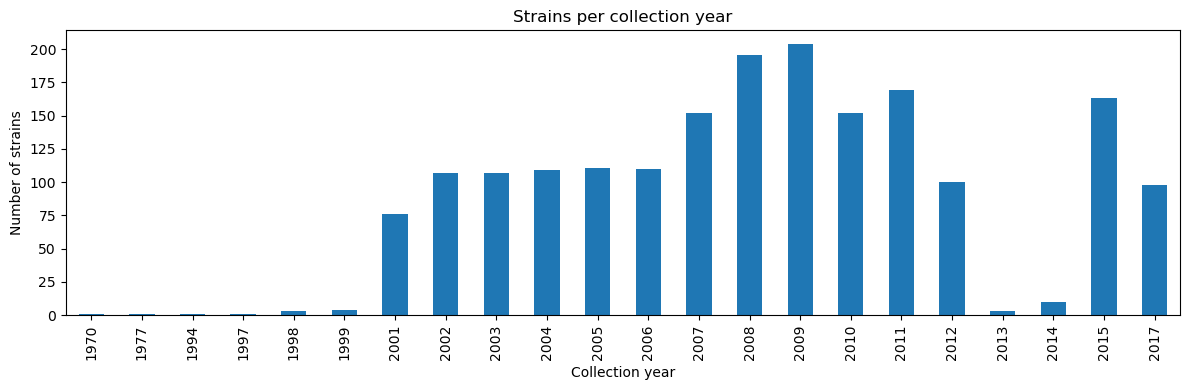

In [11]:
import matplotlib.pyplot as plt

year_counts.plot(kind="bar", figsize=(12, 4))
plt.xlabel("Collection year")
plt.ylabel("Number of strains")
plt.title("Strains per collection year")
plt.tight_layout()
plt.show()

In [12]:
print("Strains between 1970 and 2000:", year.between(1970, 2000).sum())
print("Strains between 2001 and 2012:", year.between(2001, 2012).sum())
print("Strains between 2013 and 2014:", year.between(2013, 2014).sum())
print("Strains between 2015 and 2017:", year.between(2015, 2017).sum())
print("Strains with no year:", year.isna().sum())

Strains between 1970 and 2000: 11
Strains between 2001 and 2012: 1593
Strains between 2013 and 2014: 13
Strains between 2015 and 2017: 261
Strains with no year: 58


Most strains are from 2001–2012 (1,593). There are only 11 strains from before 2000, 13 from 2013–2014, none from 2016, and 261 from 2015 and 2017. 58 strains have no year.

In [14]:
old_strains = year.between(1970, 1999)
for antibiotic in main_antibiotics:
    old_labels = labels.loc[old_strains, antibiotic].dropna()
    other_labels = labels.loc[~old_strains, antibiotic].dropna()
    print(f"{antibiotic}: old {(old_labels == 'R').sum()}/{len(old_labels)} R,   "
          f"others {(other_labels == 'R').mean():.0%} R")

CIP: old 0/11 R,   others 23% R
GEN: old 2/11 R,   others 15% R
CXM: old 1/11 R,   others 27% R


Old strains: 11 strains are from 1970–1999 (under 1% of the data). Their resistance rates are similar to or lower than the rest, as expected for older strains. They are kept for the random and lineage splits and excluded from the time split, which starts in 2001.

## Time split

In [17]:
def count_time_split(train_years, test_years):
    is_train = year.between(*train_years)
    is_test = year.between(*test_years)
    rows = []
    for antibiotic in main_antibiotics:
        train_labels = labels.loc[is_train, antibiotic].dropna()
        test_labels = labels.loc[is_test, antibiotic].dropna()
        rows.append({
            "antibiotic": antibiotic,
            "train_R": (train_labels == "R").sum(),
            "train_S": (train_labels == "S").sum(),
            "train_pct_R": round((train_labels == "R").mean() * 100, 1),
            "test_R": (test_labels == "R").sum(),
            "test_S": (test_labels == "S").sum(),
            "test_pct_R": round((test_labels == "R").mean() * 100, 1),
        })
    return pd.DataFrame(rows).set_index("antibiotic")

In [18]:
count_time_split((2001, 2012), (2015, 2017))

,train_R,train_S,train_pct_R,test_R,test_S,test_pct_R
antibiotic,,,,,,
CIP,317,1275,19.9,103,158,39.5
GEN,144,1448,9.0,124,137,47.5
CXM,320,1272,20.1,182,79,69.7


**Original plan (train 2001–2012, test 2015–2017):** resistance is much higher in the test period than in the training period (CIP: 19.9% → 39.5%, GEN: 9.0% → 47.5%, CXM: 20.1% → 69.7%). Resistance does not rise that fast naturally. To see where the high resistance comes from, the test period is split into its two years, 2015 and 2017 (there are no strains from 2016).

In [20]:
for test_year in [2015, 2017]:
    is_this_year = year == test_year
    print(test_year)
    for antibiotic in main_antibiotics:
        year_labels = labels.loc[is_this_year, antibiotic].dropna()
        print(f"  {antibiotic}: {(year_labels == 'R').sum()} R, {(year_labels == 'S').sum()} S")

2015
  CIP: 94 R, 69 S
  GEN: 119 R, 44 S
  CXM: 162 R, 1 S
2017
  CIP: 9 R, 89 S
  GEN: 5 R, 93 S
  CXM: 20 R, 78 S


2015 strains are almost all resistant. The PanPred paper also reports this, so these strains were selected for resistance. 2017 has too few resistant strains to evaluate alone. A model could score well on 2015–2017 just by telling these two groups apart, so this test period is not used. The time split is moved inside 2001–2012, which looks like one consistent collection.

In [22]:
count_time_split((2001, 2009), (2010, 2012))

,train_R,train_S,train_pct_R,test_R,test_S,test_pct_R
antibiotic,,,,,,
CIP,241,931,20.6,76,344,18.1
GEN,113,1059,9.6,31,389,7.4
CXM,261,911,22.3,59,361,14.0


**Train 2001–2009, test 2010–2012:** resistance rates are similar in train and test (CIP: 20.6% → 18.1%, GEN: 9.6% → 7.4%, CXM: 22.3% → 14.0%), so this period does not have the 2015 problem. However, GEN has only 31 resistant strains in the test set. With so few, each misclassified resistant strain changes GEN's sensitivity by about 3 percentage points, so its score would be unstable. A minimum of about 30 resistant test strains was used as the rule, and 31 only just meets it, so a split with more test data was tried next.

In [24]:
is_train_period = year.between(2001, 2008)
is_test_period = year.between(2009, 2012)

print("Train period strains:", is_train_period.sum())
print("Test period strains: ", is_test_period.sum())

Train period strains: 968
Test period strains:  625


In [25]:
count_time_split((2001, 2008), (2009, 2012))

,train_R,train_S,train_pct_R,test_R,test_S,test_pct_R
antibiotic,,,,,,
CIP,192,776,19.8,125,499,20.0
GEN,90,878,9.3,54,570,8.7
CXM,190,778,19.6,130,494,20.8


**Chosen: train 2001–2008 (968 strains), test 2009–2012 (625 strains).** All main antibiotics have over 50 resistant test strains, and resistance rates are almost the same in train and test, so a drop in performance reflects change over time rather than a different collection.

## Summary

- **Main antibiotics:** CIP (mutations), GEN (gained genes), CXM (mixed).
- **Supplementary table:** all 12 antibiotics (each has at least 100 resistant strains).
- **Old strains (1970–1999, n = 11):** kept for the random and lineage splits; outside the time split.
- **Strains without a year (n = 58):** used in the random and lineage splits only.
- **Time split:** train 2001–2008, test 2009–2012. The originally planned test period (2015–2017) was not used because 2015 strains were selected for resistance.